In [14]:
from unbiased_mcmc import *

In [15]:
import numpy as np 
def log_target0(x):
    return -0.5 * np.sum(x**2)


def log_target1(x, D):
    return -0.5 * np.sum((x - D)**2)


def g_log_target(x, path, D):
    return (1 - path) * log_target0(x) + path * log_target1(x, D)


def g_grad_log_target(x, D):
    return log_target1(x, D) - log_target0(x)

In [16]:
L = 20  # 0, 0.1, ..., 1.0
lambda_grid = np.arange(0, L + 1) / L # uniform grid of lambda values in [0, 1]

In [17]:

d = 2
Sigma = np.eye(d) # covaraince of the proposal of RWMH
mean_init = np.array([-2.0] * d) # mean for the initial distribution of MH
Sigma_init = np.eye(d) # covariance of the initial ditribution of MH
cholesky_Sigma = cholesky(Sigma)
inv_cholesky_Sigma = inv_cholesky(Sigma)


alpha = 10 #  scale 
D = alpha * np.array([1.0] * d)  # mean shift of the target distribution

log_target_path = lambda x, path: g_log_target(x, path, D)
grad_log_target_path = lambda x, path: g_grad_log_target(x, D)

In [18]:
mk_grid = tune_km_grid(
    lambda_grid,
    mean_init,
    Sigma_init,
    Sigma,
    cholesky_Sigma,
    inv_cholesky_Sigma,
    log_target_path,
    lag=1,
    nrep=1000,
)

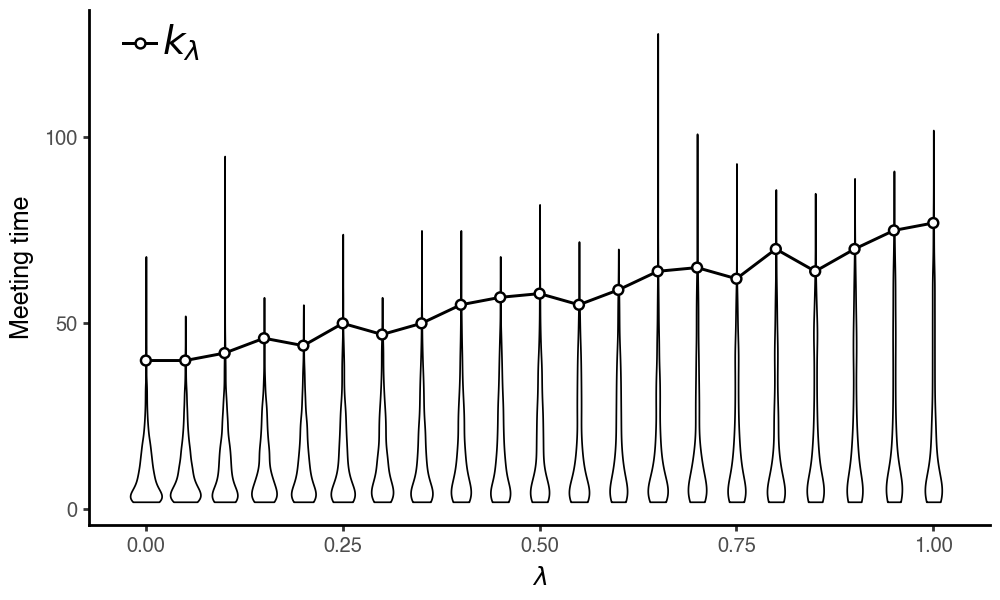

In [19]:
plot_km_grid(mk_grid, lambda_grid)

In [20]:
k_grid = mk_grid["k_grid"]
m_grid = mk_grid["m_grid"]
lag = k_grid

In [21]:
moment_results = estimate_moments(
        lambda_grid,
        k_grid,
        m_grid,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_Sigma,
        inv_cholesky_Sigma,
        log_target_path,
        grad_log_target_path,
        lag=1,
        nrep=1000,
    )

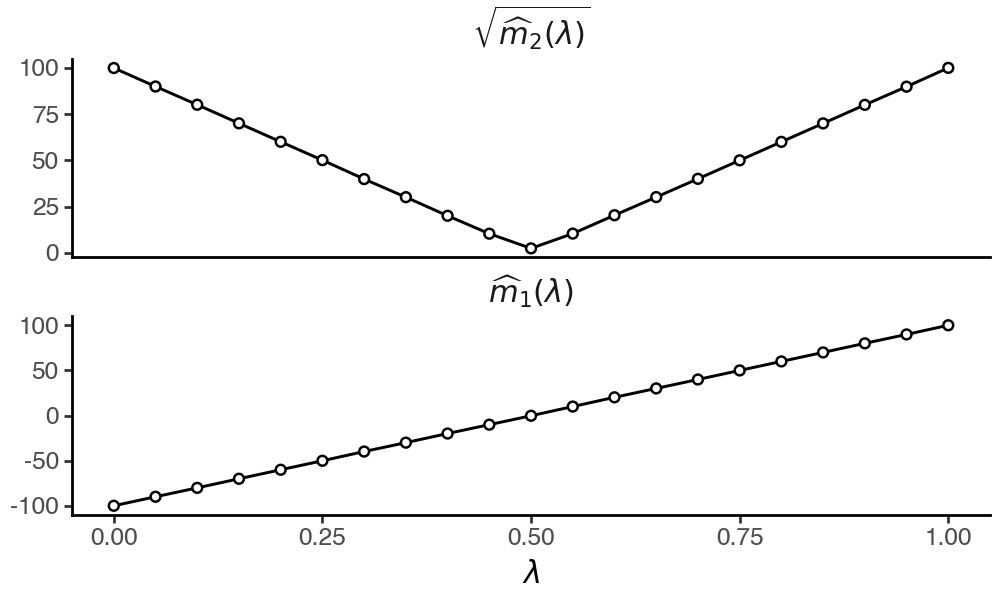

In [22]:
plot_m1_m2(moment_results, lambda_grid)

In [23]:
m2 = moment_results["m2"] # to define the optimal proposal for UPS

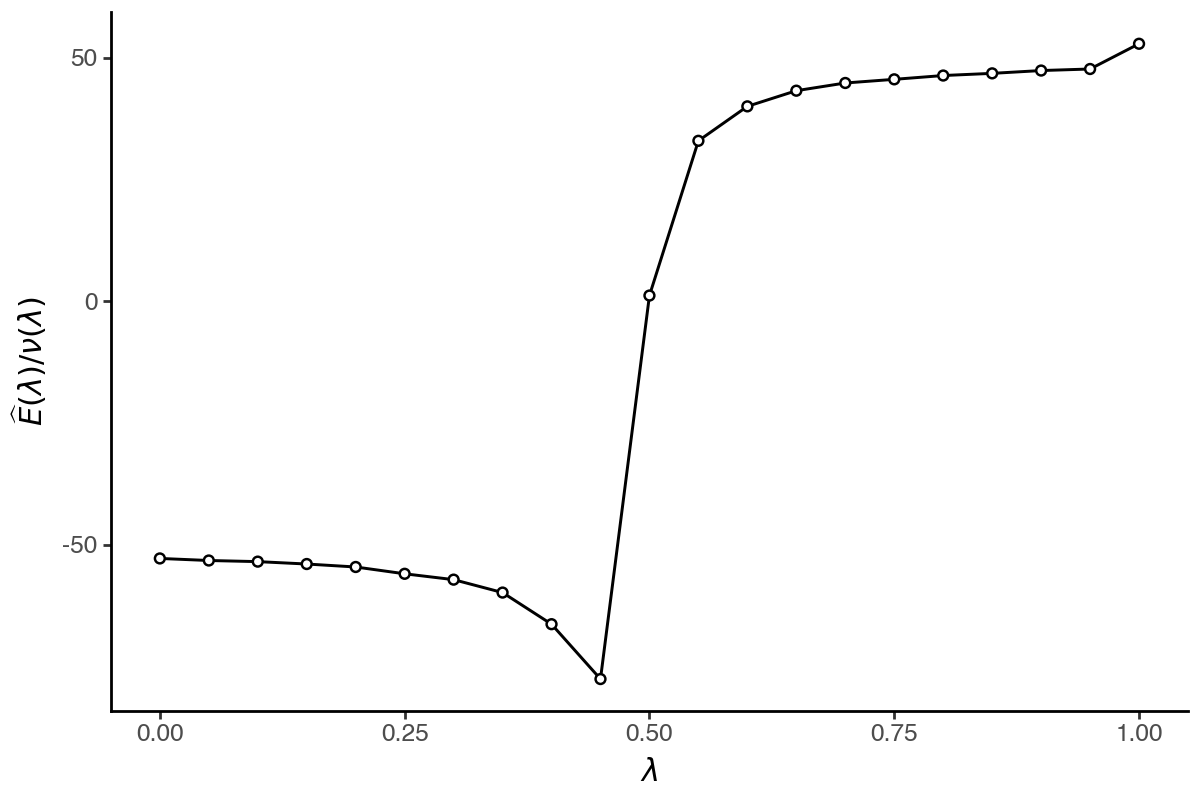

In [24]:
plot_E_lambda_over_q(
	lambda_grid,
	m2,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	nrep=500,
)

In [26]:
N_pilot = 1000
sigma = estimate_sigma(lambda_grid, k_grid, m_grid, lag, mean_init, Sigma_init, Sigma, cholesky_Sigma, inv_cholesky_Sigma, log_target_path, grad_log_target_path, N_pilot)

In [ ]:
import os
from concurrent.futures import ThreadPoolExecutor, as_completed

import pandas as pd
import plotnine as p9
from tqdm.auto import tqdm

M = 100
nrep = 500
max_workers = min(os.cpu_count() or 1, 14, 2 * nrep)
true_value = 0.0
budget = neyman_allocation(lambda_grid, sigma, M)


def run_ups(_):
    estimate, cost = UPS_estimator(
        lambda_grid,
        m2,
        k_grid,
        m_grid,
        lag,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_Sigma,
        inv_cholesky_Sigma,
        log_target_path,
        grad_log_target_path,
        M,
    )
    return float(np.asarray(estimate)), float(np.asarray(cost))


def run_sups(_):
    estimate, cost = SUPS_estimator(
        lambda_grid,
        budget,
        k_grid,
        m_grid,
        lag,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_Sigma,
        inv_cholesky_Sigma,
        log_target_path,
        grad_log_target_path,
    )
    return float(np.asarray(estimate)), float(np.asarray(cost))


UPS_results = [None] * nrep
SUPS_results = [None] * nrep
with ThreadPoolExecutor(max_workers=max_workers) as executor:
    future_methods = {}
    for index in range(nrep):
        future_methods[executor.submit(run_ups, index)] = ("UPS", index)
        future_methods[executor.submit(run_sups, index)] = ("SUPS", index)

    with tqdm(total=nrep, desc="UPS", position=0) as ups_progress, tqdm(
        total=nrep, desc="SUPS", position=1
    ) as sups_progress:
        for future in as_completed(future_methods):
            method, index = future_methods[future]
            result = future.result()
            if method == "UPS":
                UPS_results[index] = result
                ups_progress.update(1)
            else:
                SUPS_results[index] = result
                sups_progress.update(1)

UPS_values = np.asarray([result[0] for result in UPS_results])
UPS_costs = np.asarray([result[1] for result in UPS_results])
SUPS_values = np.asarray([result[0] for result in SUPS_results])
SUPS_costs = np.asarray([result[1] for result in SUPS_results])

M_is = max(1, int(round((UPS_costs.mean() + SUPS_costs.mean()) / 2)))
IS_values = np.empty(nrep)
for start in tqdm(range(0, nrep, max_workers), desc="IS batches"):
    batch_size = min(max_workers, nrep - start)
    samples = np.random.normal(size=(batch_size, M_is, d))
    log_weights = -0.5 * np.sum((samples - D) ** 2, axis=2) + 0.5 * np.sum(
        samples**2, axis=2
    )
    IS_values[start : start + batch_size] = (
        np.logaddexp.reduce(log_weights, axis=1) - np.log(M_is)
    )

comparison_mse = {
    "UPS": np.mean((UPS_values - true_value) ** 2),
    "SUPS": np.mean((SUPS_values - true_value) ** 2),
    "IS": np.mean((IS_values - true_value) ** 2),
}
comparison_results = {
    "UPS_values": UPS_values,
    "UPS_costs": UPS_costs,
    "SUPS_values": SUPS_values,
    "SUPS_costs": SUPS_costs,
    "IS_values": IS_values,
    "M_is": M_is,
    "MSE": comparison_mse,
}


/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
IS batches: 100%|██████████| 36/36 [00:00<00:00, 72.57it/s]


Workers=14 | M_IS=20652 | coût moyen UPS=20656.0 | coût moyen SUPS=20647.2
MSE: {'UPS': np.float64(51.66132071437975), 'SUPS': np.float64(0.8181162568307817), 'IS': np.float64(2806.6214785951133)}


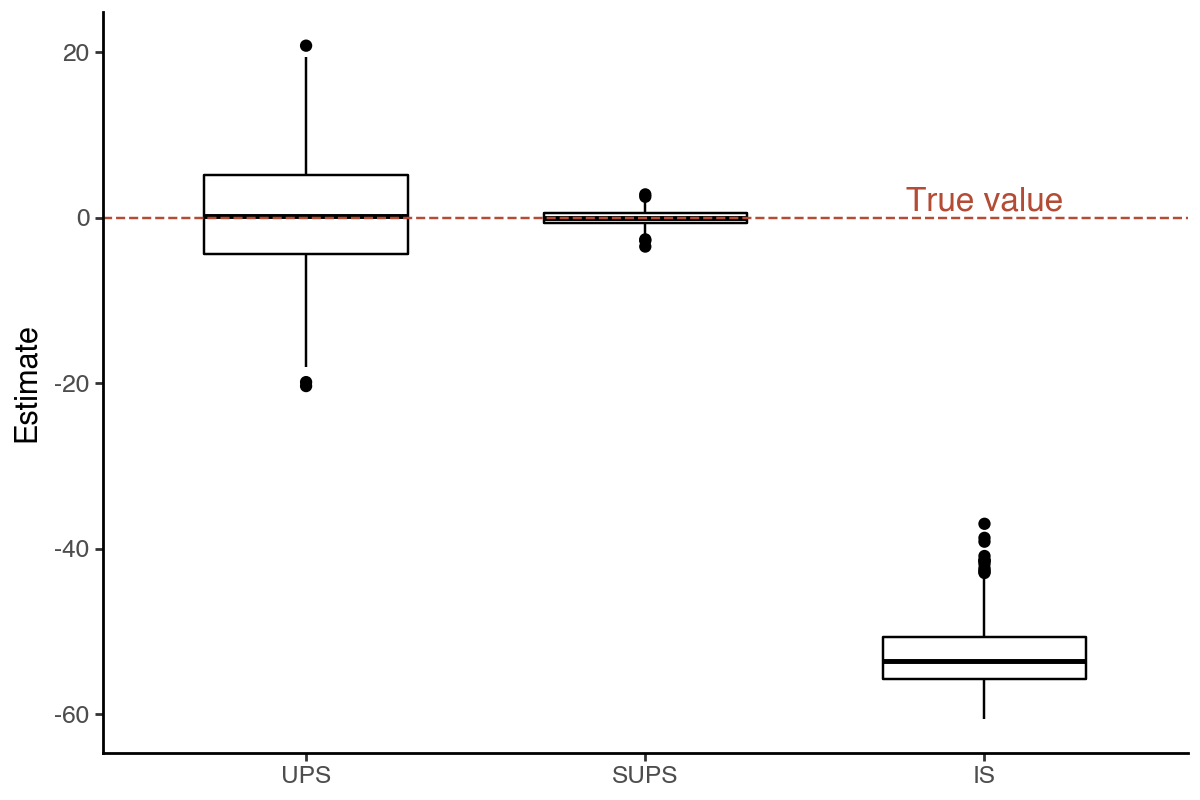

In [16]:
print(
    f"Workers={max_workers} | M_IS={M_is} | "
    f"coût moyen UPS={UPS_costs.mean():.1f} | "
    f"coût moyen SUPS={SUPS_costs.mean():.1f}"
)
print("MSE:", comparison_mse)

plot_data = pd.DataFrame(
    {
        "Estimate": np.concatenate([UPS_values, SUPS_values, IS_values]),
        "Estimator": np.repeat(["UPS", "SUPS", "IS"], nrep),
    }
)
plot_data["Estimator"] = pd.Categorical(
    plot_data["Estimator"],
    categories=["UPS", "SUPS", "IS"],
    ordered=True,
)
true_value_label = pd.DataFrame(
    {"Estimator": ["IS"], "Estimate": [true_value], "label": ["True value"]}
)
comparison_plot = (
    p9.ggplot(plot_data, p9.aes(x="Estimator", y="Estimate"))
    + p9.geom_boxplot(width=0.6, fill="white", color="black", size=0.5)
    + p9.geom_hline(
        yintercept=true_value,
        linetype="dashed",
        color="#b44b35",
        size=0.5,
    )
    + p9.geom_text(
        data=true_value_label,
        mapping=p9.aes(x="Estimator", y="Estimate", label="label"),
        inherit_aes=False,
        ha="center",
        va="bottom",
        color="#b44b35",
        size=12,
    )
    + p9.labs(x="", y="Estimate", title=None)
    + p9.theme_classic(base_size=11)
    + p9.theme(figure_size=(6, 4))
)
comparison_plot